# Diabetes Prediction with Logistic Regression

**Question:** Can a simple, explainable model flag patients at higher risk of diabetes from routine health measurements?

**Dataset:** Pima Indians Diabetes dataset: 768 patients, 8 health measurements and the outcome (1 = diabetic, 0 = not diabetic).

**Steps:** EDA, treating impossible zero values as missing, train-test split, scaling, logistic regression, evaluation (accuracy, precision, recall, F1, ROC curve), coefficient interpretation, saving the model for a Streamlit app.

In [1]:
import pandas as pd 
import numpy as np 

In [2]:
df = pd.read_csv('../data/diabetes.csv')

## 1. Explore the data

In [3]:
df.head()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 9 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Pregnancies               768 non-null    int64  
 1   Glucose                   768 non-null    int64  
 2   BloodPressure             768 non-null    int64  
 3   SkinThickness             768 non-null    int64  
 4   Insulin                   768 non-null    int64  
 5   BMI                       768 non-null    float64
 6   DiabetesPedigreeFunction  768 non-null    float64
 7   Age                       768 non-null    int64  
 8   Outcome                   768 non-null    int64  
dtypes: float64(2), int64(7)
memory usage: 54.1 KB


In [5]:
# Great all columns are good we have no null values 2 colums are float rest all integer 

In [6]:
df.describe()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
count,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000
mean,3.845052,120.894531,69.105469,20.536458,79.799479,31.992578,0.471876,33.240885,0.348958
std,3.369578,31.972618,19.355807,15.952218,115.244002,7.884160,0.331329,11.760232,0.476951
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.078000,21.000000,0.000000
25%,1.000000,99.000000,62.000000,0.000000,0.000000,27.300000,0.243750,24.000000,0.000000
50%,3.000000,117.000000,72.000000,23.000000,30.500000,32.000000,0.372500,29.000000,0.000000
75%,6.000000,140.250000,80.000000,32.000000,127.250000,36.600000,0.626250,41.000000,1.000000
max,17.000000,199.000000,122.000000,99.000000,846.000000,67.100000,2.420000,81.000000,1.000000


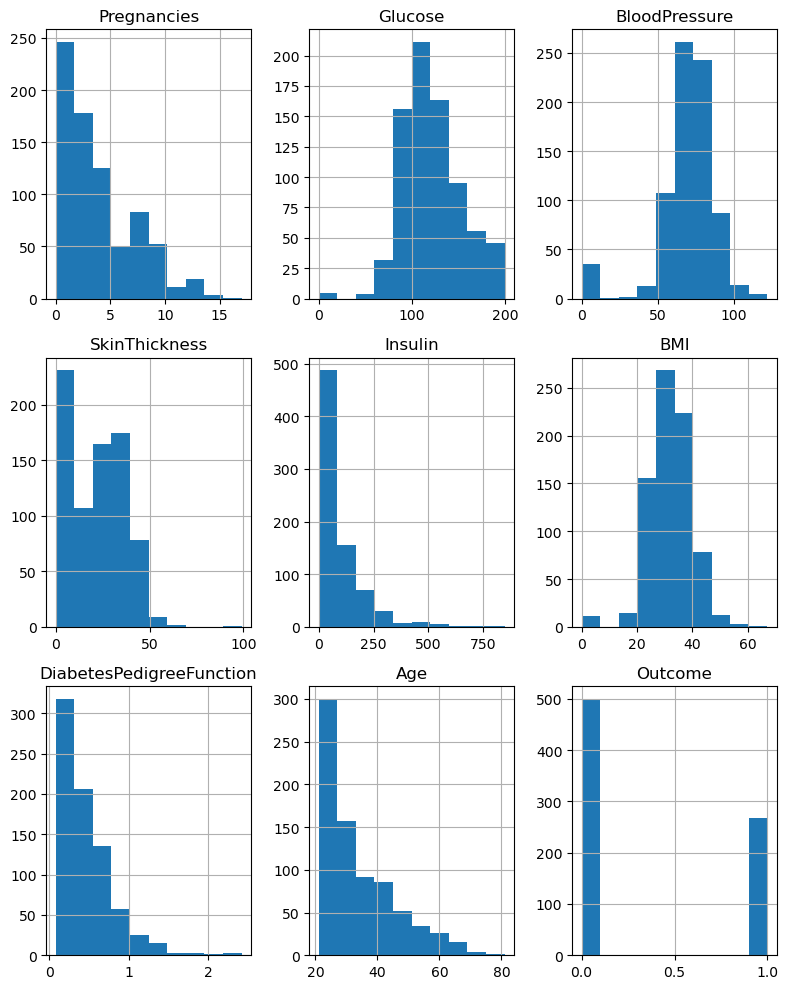

In [7]:
import matplotlib.pyplot as plt

df.hist(figsize=(8,10))
plt.tight_layout()
plt.show()

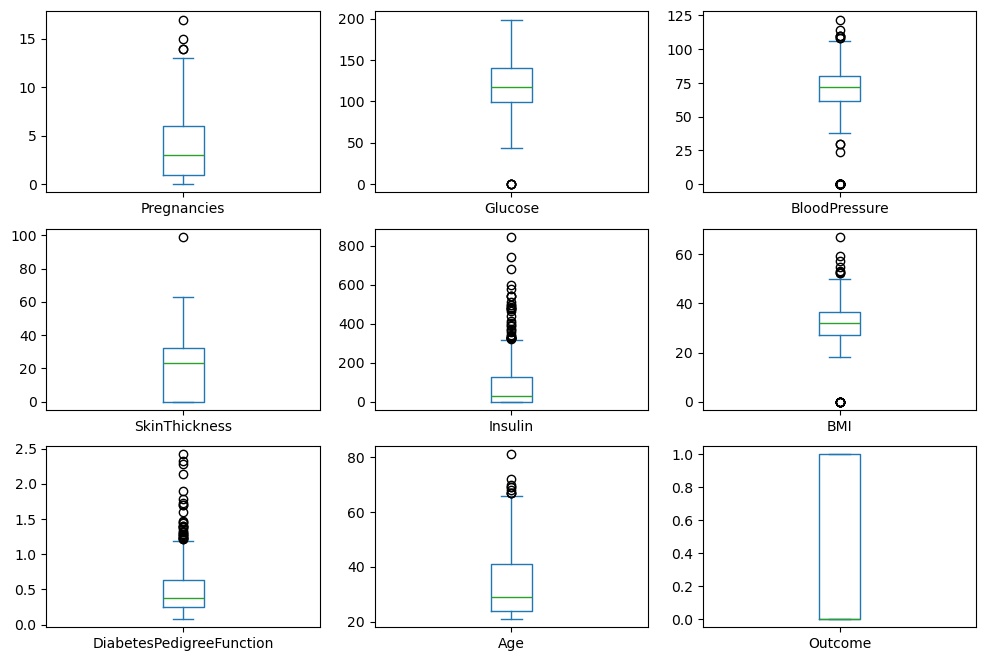

In [8]:
df.plot(kind='box',subplots=True, layout=(3,3), figsize=(12,8))
plt.show()

Insulin contains several extreme values, indicating the presence of outliers that may affect model performance.

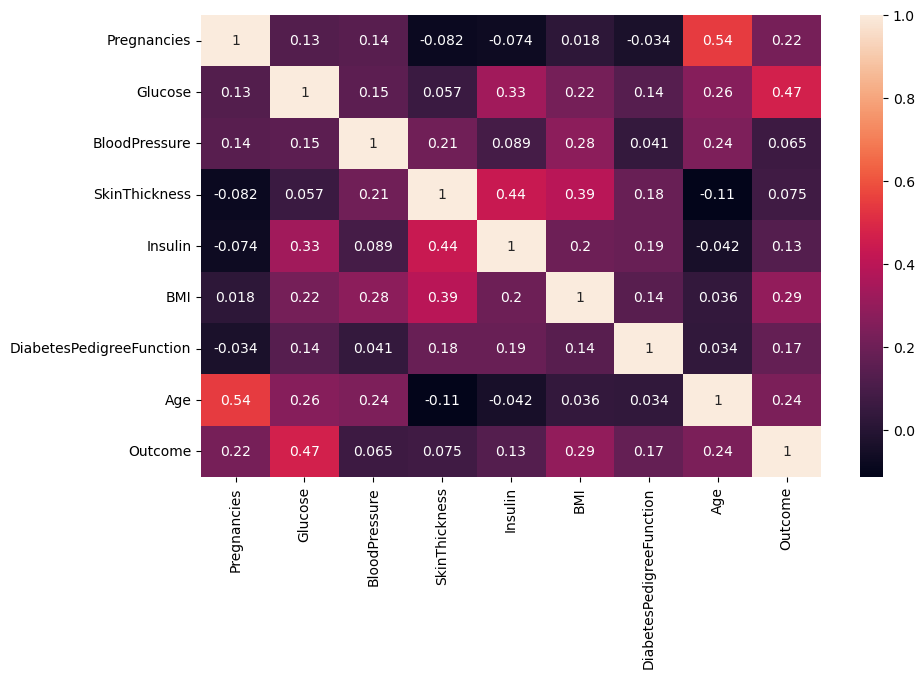

In [9]:
import seaborn as sns 
plt.figure(figsize=(10,6))
sns.heatmap(df.corr(), annot=True)
plt.show()

The heatmap showed that Glucose had the strongest positive correlation with Outcome, suggesting it is the most important predictor of diabetes.



## 2. Clean the data: zeros treated as missing values

In [10]:
cols = ['Glucose', 'BloodPressure', 'SkinThickness', 'Insulin', 'BMI']

df[cols] = df[cols].replace(0, pd.NA)
# There is 0 present in many rows as glucose, insulin, etc can't be 0 practically it might 
# not be recorded so we are replacing it with NA

In [11]:
df.fillna(df.median(),inplace=True)
# Here we replace null values with the median of each column. The median is the middle value,
# so it is less affected by extreme values (like the very high Insulin readings) than the mean.  

C:\Users\ASUS\AppData\Local\Temp\ipykernel_25532\3697087951.py:1: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  df.fillna(df.median(),inplace=True)


## 3. Split and scale

In [12]:
# Now here we split for x and y variable, x being independent and y the output being dependent 
x = df.drop('Outcome', axis=1)
y = df['Outcome']

In [13]:
# Train-Test-Split 
from sklearn.model_selection import train_test_split
xtrain,xtest,ytrain,ytest = train_test_split(x,y,test_size=0.2,random_state=42)

In [14]:
#Let's scale the values before logistic regression so some freatures don't dominat the model
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

xtrain = scaler.fit_transform(xtrain)
xtest = scaler.fit_transform(xtest)

## 4. Train the logistic regression model

In [15]:
# Logistic Regression 
from sklearn.linear_model import LogisticRegression

model = LogisticRegression()
model.fit(xtrain,ytrain)

LogisticRegression()

In [16]:
#Prediction
y_pred = model.predict(xtest)
y_prob = model.predict_proba(xtest)[:,1]

## 5. Evaluate the model

In [17]:
#Accuracy Score
from sklearn.metrics import accuracy_score

accuracy = accuracy_score(ytest, y_pred)
print("Accuracy:", accuracy)

Accuracy: 0.7662337662337663


*Note: the two cells below were not run in the original submission. Their outputs were generated later by running the same code.*

In [ ]:
#Precision, Recall, F1
from sklearn.metrics import classification_report

print(classification_report(ytest, y_pred))

              precision    recall  f1-score   support

           0       0.80      0.85      0.82        99
           1       0.69      0.62      0.65        55

    accuracy                           0.77       154
   macro avg       0.75      0.73      0.74       154
weighted avg       0.76      0.77      0.76       154



In [ ]:
from sklearn.metrics import roc_auc_score 
roc_auc = roc_auc_score(ytest, y_pred)
print('roc_auc_score:',roc_auc)

roc_auc_score: 0.7333333333333334


*Correction added later: ROC-AUC should be calculated from predicted probabilities (`y_prob`), not predicted classes. The cell above is kept as originally written. The cell below uses the same model and test set; this value matches the ROC curve plotted next.*

In [ ]:
roc_auc_prob = roc_auc_score(ytest, y_prob)
print('roc_auc_score (from probabilities):', roc_auc_prob)

roc_auc_score (from probabilities): 0.8233241505968778


In [19]:
from sklearn.metrics import roc_curve

fpr, tpr, thresholds = roc_curve(ytest, y_prob)

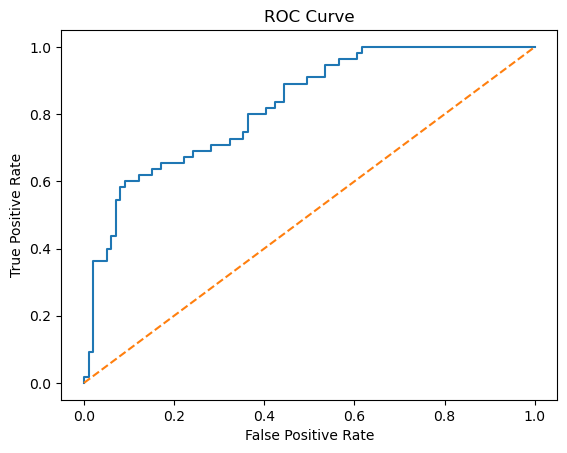

In [20]:
plt.plot(fpr, tpr)
plt.plot([0,1],[0,1],'--')
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve")
plt.show()

## 6. Interpret the coefficients

In [21]:
coef_df = pd.DataFrame({
    'Feature': x.columns,
    'Coefficient': model.coef_[0]
})

print(coef_df)

                    Feature  Coefficient
0               Pregnancies     0.222978
1                   Glucose     1.102682
2             BloodPressure    -0.151540
3             SkinThickness     0.068836
4                   Insulin    -0.138252
5                       BMI     0.688839
6  DiabetesPedigreeFunction     0.203635
7                       Age     0.392410


In [22]:
# Glucose has a positive coefficient, indicating that higher glucose levels increase the likelihood of diabetes.
# Not all features contribute equally some matter a lot, some barely matter Glucose is the most important feature 
# BMI moderatly important 
# Age and Pregnancy some effect 
# Other are very weak in order to consider them 

## 7. Save the model and scaler for the Streamlit app

In [23]:
# Model saving deployment 
import pickle 
pickle.dump(model, open('model.pkl','wb'))
# dump - stores object into a file 
# model - our trained lr model 
# wb - write binary 
pickle.dump(scaler, open("scaler.pkl", "wb"))


## Interview questions

### 1. Difference between Precision and Recall

Precision measures how many of the instances predicted as positive are actually positive.
It focuses on reducing false positives.

Recall measures how many of the actual positive instances were correctly identified by the model. It focuses on reducing false negatives.

### What is Cross-Validation and Why is it Important in Binary Classification?

Cross-validation is a model evaluation technique where the dataset is divided into multiple subsets (folds).
The model is trained on some folds and tested on the remaining fold, repeating the process several times.

In binary classification, cross-validation helps confirm that the model can classify both classes accurately across different samples.